# Customer Retention & Revenue Intelligence — Exploratory Analysis

**Dataset:** IBM Telco Customer Churn (7,043 fictional customers, 21 columns)
**Purpose:** understand why customers leave, where revenue is exposed, and who the
retention team should call first.

This notebook reads the artefacts produced by the pipeline (`python main.py all`),
so every number here is the same number the reports and dashboard use.

> **Scope.** Cross-sectional customer churn. Not a time-series forecast — the
> dataset has no dates. All findings are associations, not causal effects.

In [1]:
import sys
from pathlib import Path

# Make the project importable when the notebook runs from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

def show(path):
    """Render a saved figure inline at a readable width."""
    path = Path(path)
    if not path.is_absolute():
        path = ROOT / path
    return display(Image(filename=str(path), width=880))

import config
from src.data.cleaning import load_clean
from src.analytics import style

style.apply_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)

print("Project root:", ROOT)
print("pandas", pd.__version__)

Project root: C:\Users\Asba\Desktop\Projects\customer_churn
pandas 3.0.0


## 1. Load the cleaned dataset

The raw CSV is never modified. `src/data/cleaning.py` produces
`data/processed/telco_churn_clean.csv` with documented imputation and derived
features. See `reports/data_quality_report.md` for the audit trail.

In [2]:
df = load_clean()
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 7,043 rows x 33 columns


,customer_id,gender,senior_citizen,senior_citizen_label,partner,dependents,tenure,tenure_group,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,auto_payment,monthly_charges,total_charges,total_charges_imputed,avg_monthly_charge,num_addon_services,has_internet,service_count,revenue_band,high_value_customer,churn,churn_label,data_quality_flag
0,7590-VHVEG,Female,0,No,1,0,1,0-6 months,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,0,29.85,29.85,0,29.85,1,1,2,Low,0,No,0,0
1,5575-GNVDE,Male,0,No,0,0,34,25-48 months,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,0,56.95,1889.50,0,55.57,2,1,4,Mid-Low,0,No,0,0
2,3668-QPYBK,Male,0,No,0,0,2,0-6 months,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,0,53.85,108.15,0,54.08,2,1,4,Mid-Low,0,Yes,1,0
3,7795-CFOCW,Male,0,No,0,0,45,25-48 months,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),1,42.30,1840.75,0,40.91,3,1,4,Mid-Low,0,No,0,0
4,9237-HQITU,Female,0,No,0,0,2,0-6 months,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,0,70.70,151.65,0,75.82,0,1,2,Mid-High,0,Yes,1,0


In [3]:
# Business KPI baseline — computed, not asserted
kpis = {
    "total_customers": len(df),
    "churned": int((df["churn"] == "Yes").sum()),
    "retained": int((df["churn"] == "No").sum()),
    "churn_rate": df["churn_label"].mean(),
    "avg_tenure": df["tenure"].mean(),
    "avg_monthly_charges": df["monthly_charges"].mean(),
    "monthly_revenue": df["monthly_charges"].sum(),
    "monthly_revenue_churned": df.loc[df["churn_label"] == 1, "monthly_charges"].sum(),
}
for key, value in kpis.items():
    print(f"{key:28s} {value:,.4f}" if isinstance(value, float) else f"{key:28s} {value:,}")

total_customers              7,043
churned                      1,869
retained                     5,174
churn_rate                   0.2654
avg_tenure                   32.3711
avg_monthly_charges          64.7617
monthly_revenue              456,116.6000
monthly_revenue_churned      139,130.8500


### Reading the numbers

Churn sits at **26.5%** — a genuine minority class. That single fact drives most
methodological choices downstream: accuracy is a useless headline metric, PR-AUC
and lift are the honest ones, and the model needs explicit imbalance handling.

Note also that churners carry a **higher average monthly charge** than retained
customers. The customers leaving are the expensive ones.

## 2. Churn distribution

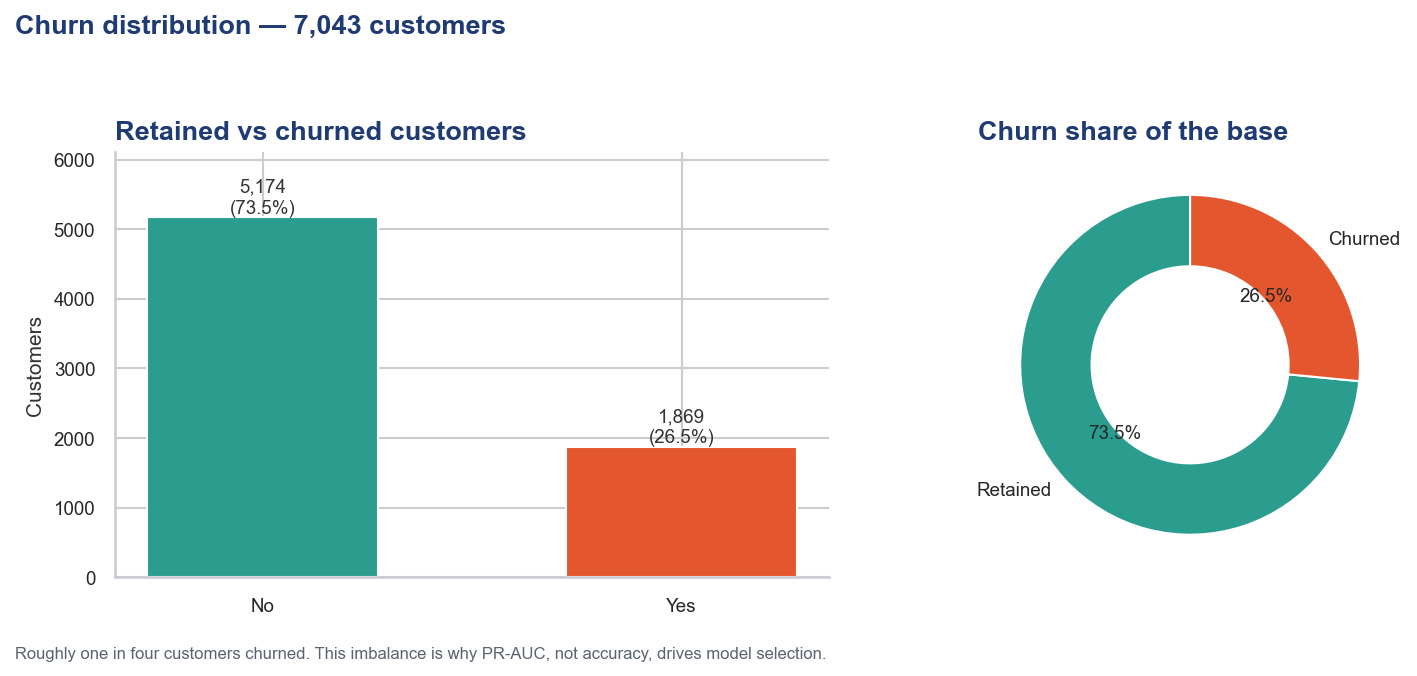

Saved: data/exports/figures/01_churn_distribution.png


In [4]:
from src.analytics.eda import plot_churn_distribution
path = plot_churn_distribution(df)
show(path)
print("Saved:", path)

**Observed:** 5,174 retained vs 1,869 churned (26.5% churn).
**Why it matters:** a naive "nobody churns" model would score 73.5% accuracy and be
worthless. Every metric reported later is read against this base rate.

## 3. Tenure — the strongest continuous signal

In [5]:
from src.analytics.churn_analysis import churn_by_tenure_group

tenure_table = churn_by_tenure_group(df)
tenure_table[["tenure_group", "customers", "churned", "churn_rate", "avg_tenure", "monthly_revenue_at_risk"]]

,tenure_group,customers,churned,churn_rate,avg_tenure,monthly_revenue_at_risk
0,0-6 months,1481,784,0.529372,2.5,49896.10
1,7-12 months,705,253,0.358865,9.4,19058.15
2,13-24 months,1024,294,0.287109,18.4,23081.65
3,25-48 months,1594,325,0.203890,36.2,27462.50
4,49+ months,2239,213,0.095132,63.0,19632.45


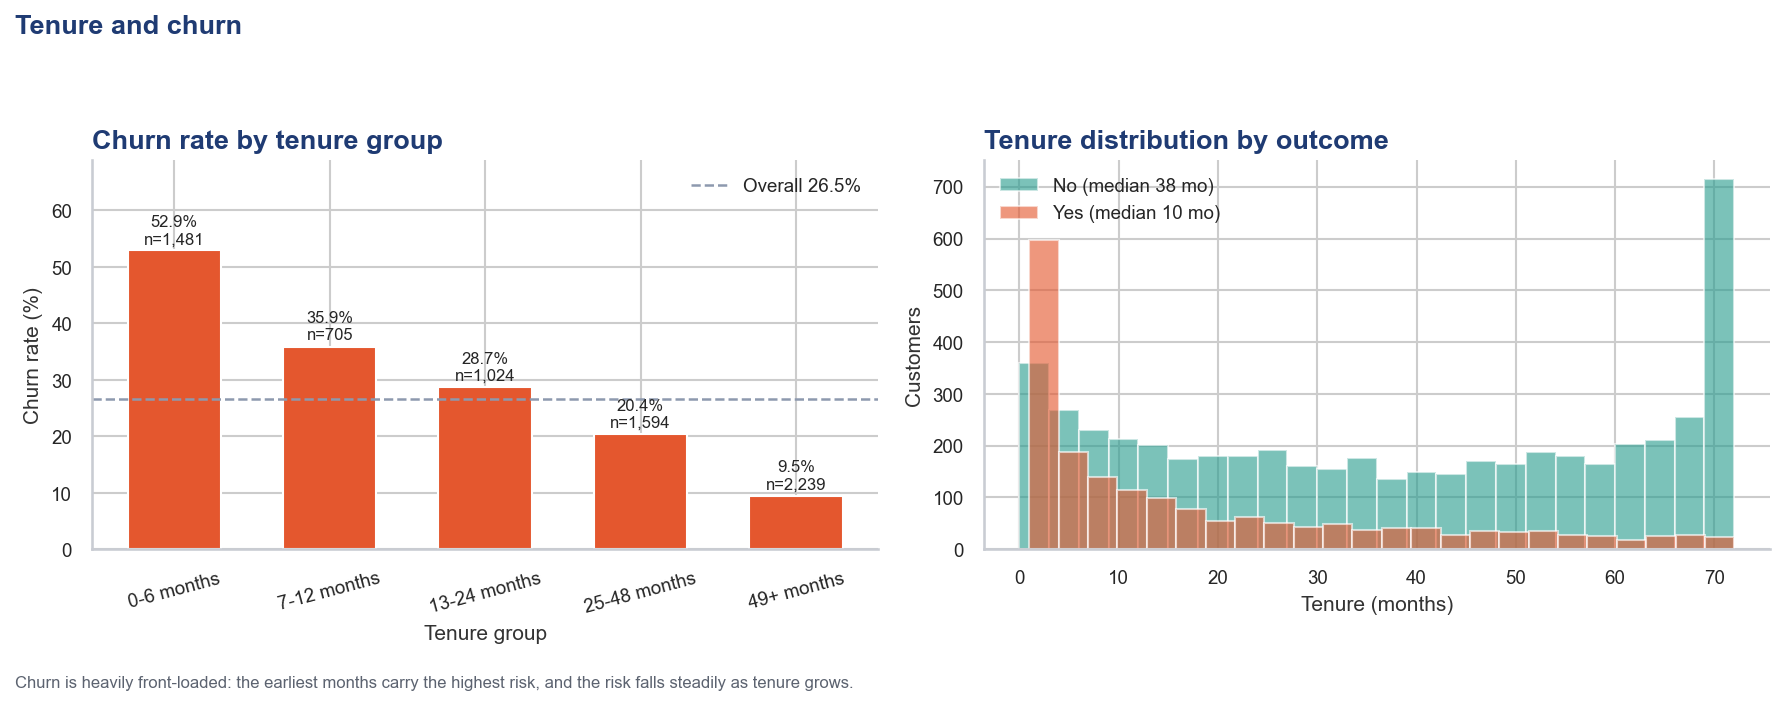

In [6]:
from src.analytics.eda import plot_tenure_analysis
show(plot_tenure_analysis(df))

**Observed:** the 0–6 month cohort churns at **52.9%**, falling monotonically to
**9.5%** for customers past 48 months. Median tenure is 10 months for churners
versus 38 for retained customers.

**Why it matters:** churn is front-loaded. Retention spend in the first 90 days
has far more leverage than the same spend on a three-year customer.

**What to investigate next:** onboarding quality, first-bill shock, early support
ticket volume, and whether the first contract renewal is where customers decide.

**Caveat:** tenure and churn are observed at the same instant. A customer with
long tenure has already survived many churn opportunities, so part of this pattern
is survivorship rather than a protective effect of time itself.

## 4. Contract type — the sharpest structural split

In [7]:
from src.analytics.churn_analysis import churn_by_contract
churn_by_contract(df)[["contract", "customers", "churned", "churn_rate", "lift_vs_baseline",
                       "monthly_revenue", "monthly_revenue_at_risk"]]

,contract,customers,churned,churn_rate,lift_vs_baseline,monthly_revenue,monthly_revenue_at_risk
0,Month-to-month,3875,1655,0.427097,1.61,257294.15,120847.10
1,One year,1473,166,0.112695,0.42,95816.60,14118.45
2,Two year,1695,48,0.028319,0.11,103005.85,4165.30


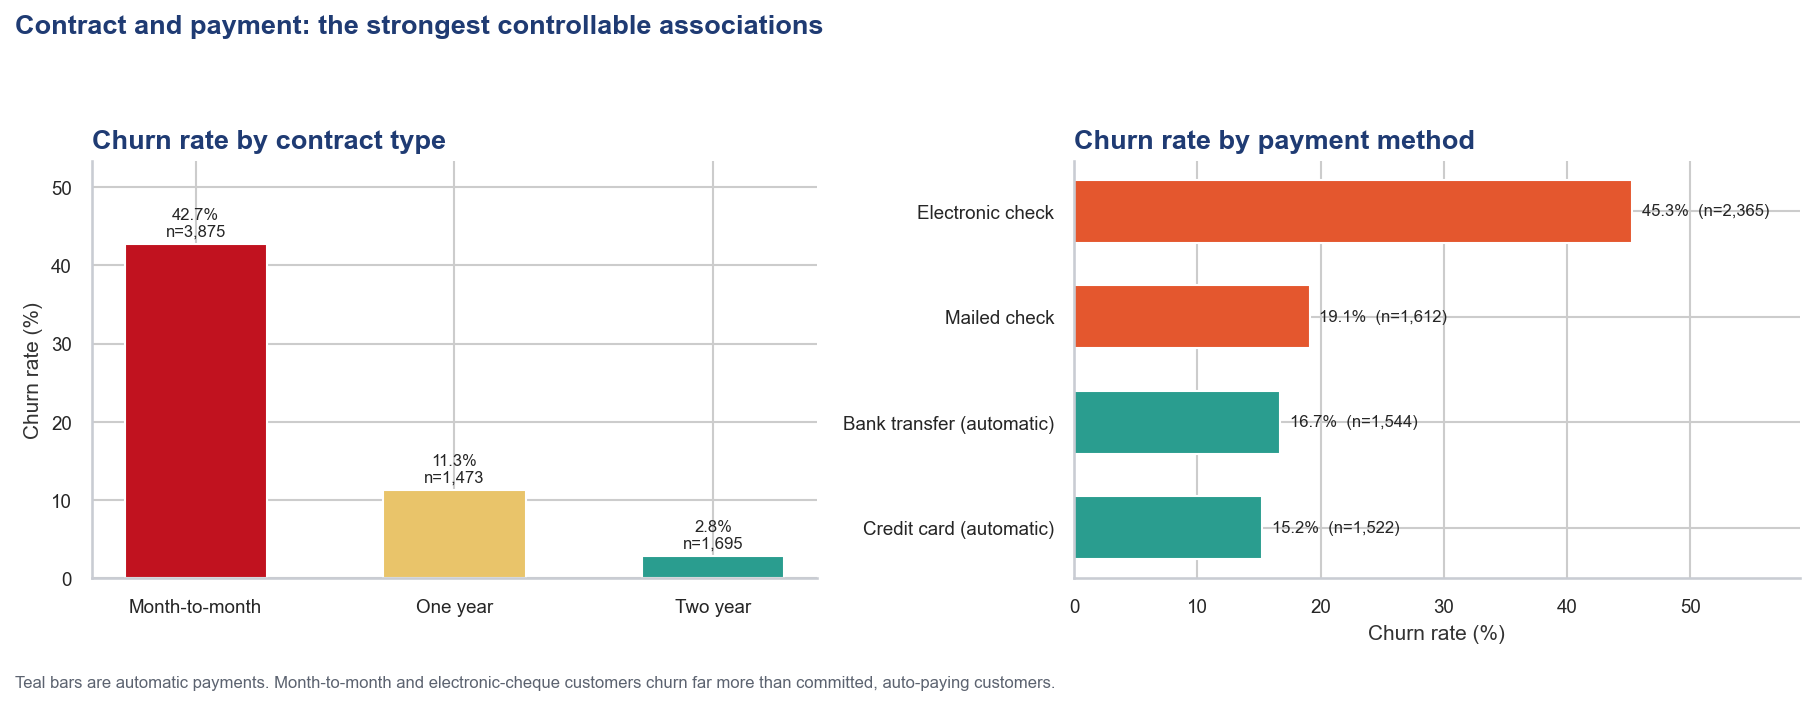

In [8]:
from src.analytics.eda import plot_contract_and_payment
show(plot_contract_and_payment(df))

**Observed:** Month-to-month churns at **42.7%** (1.61× base); two-year contracts at
**2.8%** (0.11× base). A 40-percentage-point spread.

**Why it matters:** this is the single largest controllable lever in the dataset.
Month-to-month customers also hold the majority of exposed revenue.

**What to investigate next:** the economics of converting month-to-month customers
to fixed terms — what discount is needed, and what the resulting margin looks like
after accounting for the churn avoided.

**Caveat:** contract choice is not random. Customers who accept a two-year term may
already be more settled, more price-insensitive, or planning to stay. The observed
gap is an association, and part of it is selection.

## 5. Payment method

In [9]:
from src.analytics.churn_analysis import churn_by_payment_method
churn_by_payment_method(df)[["payment_method", "auto_payment", "customers", "churn_rate",
                             "lift_vs_baseline", "monthly_revenue_at_risk"]]

,payment_method,auto_payment,customers,churn_rate,lift_vs_baseline,monthly_revenue_at_risk
0,Electronic check,0,2365,0.452854,1.71,84288.75
1,Mailed check,0,1612,0.191067,0.72,16803.60
2,Bank transfer (automatic),1,1544,0.167098,0.63,20091.90
3,Credit card (automatic),1,1522,0.152431,0.57,17946.60


**Observed:** electronic check churns at **45.3%**; automatic bank transfer and
credit card both sit near **15–17%**.

**Why it matters:** enrolling customers in automatic payment is operationally cheap
relative to any pricing change, and it removes a monthly moment where the customer
actively re-decides to stay.

**What to investigate next:** whether the payment method itself matters, or whether
it proxies for something else (income stability, tech comfort, engagement). A
targeted enrolment test with a control group would answer this properly.

## 6. Services and add-on depth

In [10]:
from src.analytics.churn_analysis import churn_by_addon, churn_by_internet_service
display(churn_by_internet_service(df)[["internet_service", "customers", "churn_rate", "monthly_revenue_at_risk"]])
churn_by_addon(df)[["addon", "churn_rate_with", "churn_rate_without", "difference_pts"]]

,internet_service,customers,churn_rate,monthly_revenue_at_risk
0,Fiber optic,3096,0.418928,114300.05
1,DSL,2421,0.189591,22529.20
2,No,1526,0.074050,2301.60


,addon,churn_rate_with,churn_rate_without,difference_pts
0,Online Security,0.1461,0.4177,-27.16
3,Tech Support,0.1517,0.4164,-26.47
1,Online Backup,0.2153,0.3993,-18.40
2,Device Protection,0.2250,0.3913,-16.63
5,Streaming Movies,0.2994,0.3368,-3.74
4,Streaming Tv,0.3007,0.3352,-3.45


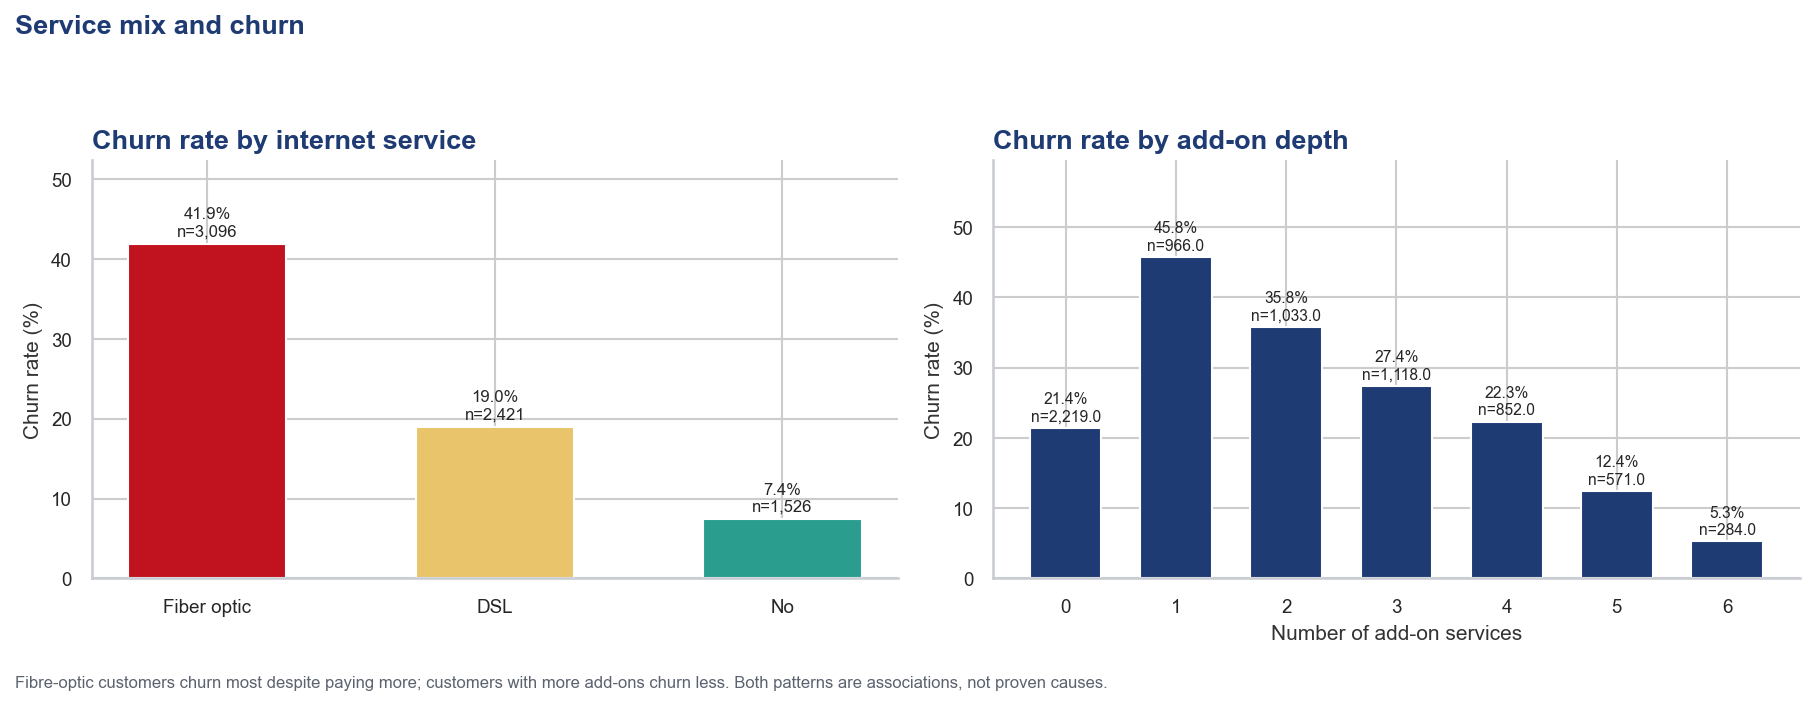

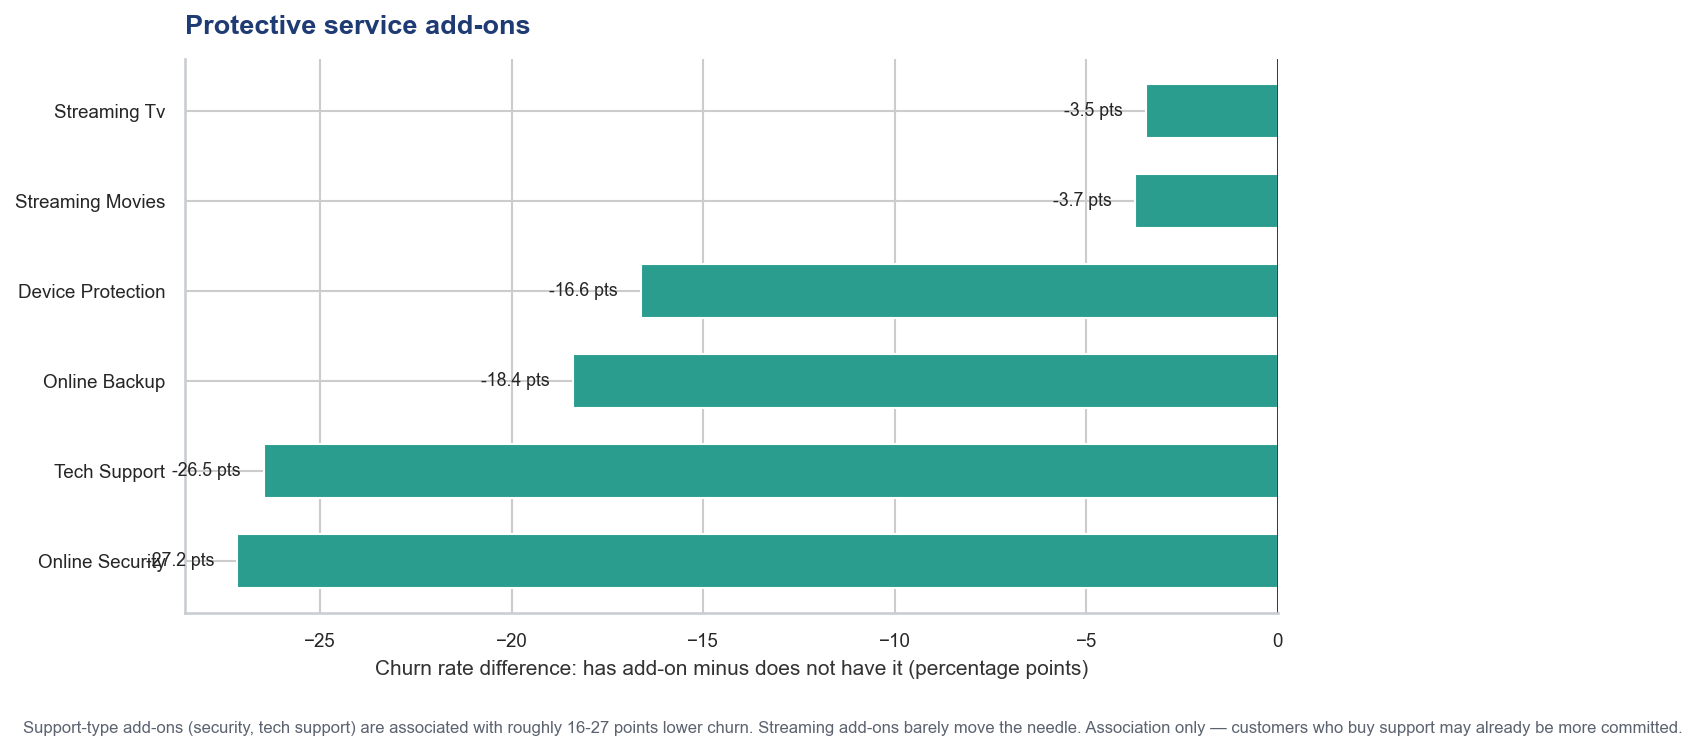

In [11]:
from src.analytics.eda import plot_service_analysis, plot_addon_effect
show(plot_service_analysis(df))
show(plot_addon_effect(df))

**Observed:** fibre-optic churns at **41.9%** — higher than DSL (19.0%) despite
costing more. Add-on depth is protective: online security shows a
**27.2-point** churn gap, tech support **26.5 points**.

**Why it matters:** the fibre paradox is the most surprising finding and the one
worth the most investigation. Customers paying a premium for the best product are
leaving fastest.

**What to investigate next:** fibre price sensitivity, competitor fibre offers in
the same service areas, installation and reliability issues, and whether support
add-ons are being sold to the customers who need them most.

**Caveat:** add-on adoption correlates with engagement. Customers who buy security
and support may already be committed; buying the add-on may not be what keeps them.

## 7. Charges and revenue exposure

In [12]:
from src.analytics.revenue_analysis import revenue_summary, revenue_concentration
summary = revenue_summary(df)
for key in ["total_monthly_revenue", "monthly_revenue_churned", "revenue_share_churned",
            "avg_monthly_charge_churned", "avg_monthly_charge_retained"]:
    print(f"{key:32s} {summary[key]:>14,.2f}")
print()
for key, value in revenue_concentration(df).items():
    print(f"{key:32s} {value}")

total_monthly_revenue                456,116.60
monthly_revenue_churned              139,130.85
revenue_share_churned                      0.30
avg_monthly_charge_churned                74.44
avg_monthly_charge_retained               61.27

total_monthly_revenue            456116.6
top_1pct_revenue_share           0.0178
top_5pct_revenue_share           0.0861
top_10pct_revenue_share          0.1671
top_20pct_revenue_share          0.3186
revenue_per_customer_monthly     64.76
high_value_threshold             89.85


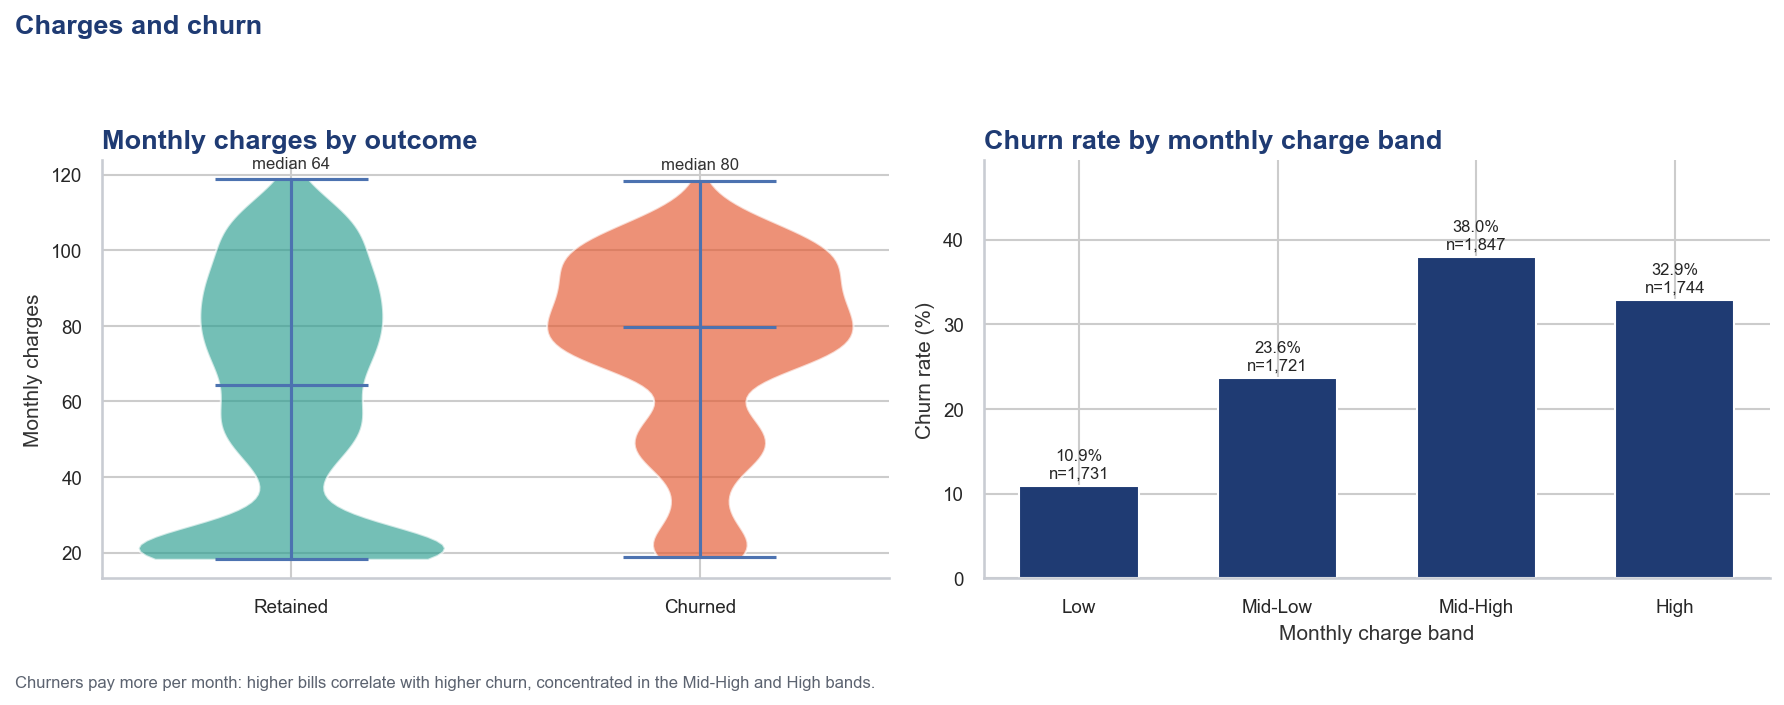

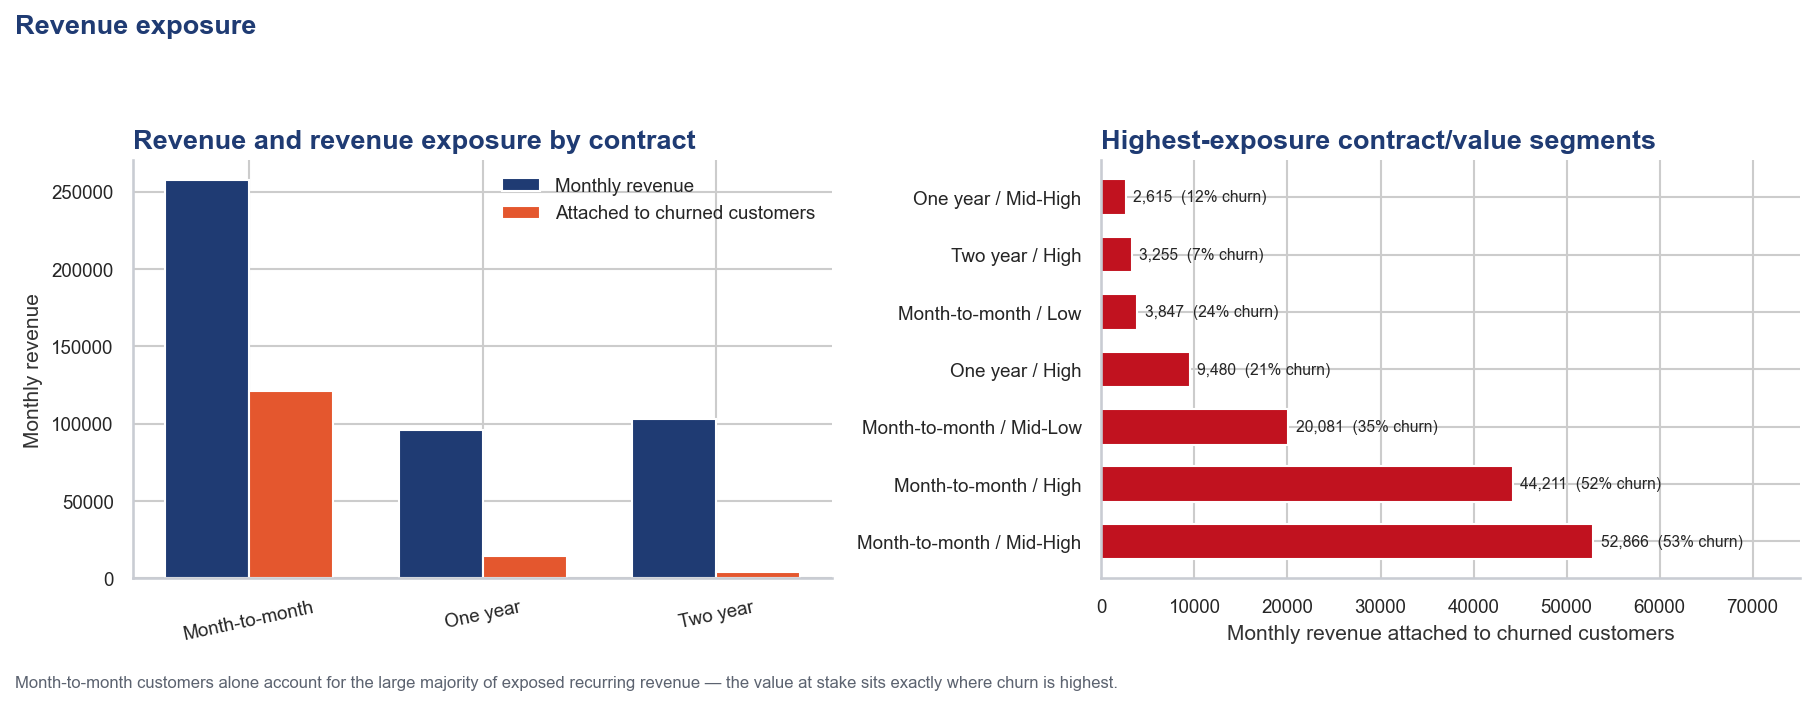

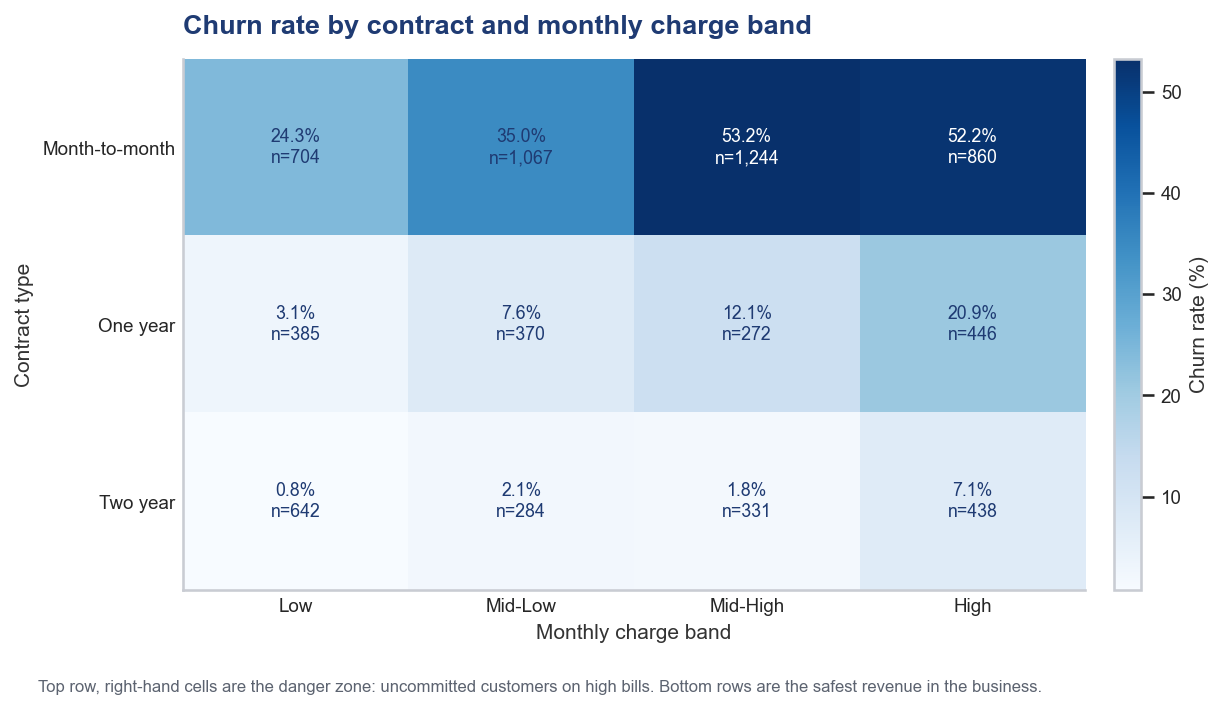

In [13]:
from src.analytics.eda import plot_charges_analysis, plot_revenue_exposure, plot_segment_heatmap
show(plot_charges_analysis(df))
show(plot_revenue_exposure(df))
show(plot_segment_heatmap(df))

**Observed:** **139,131** in monthly recurring charges sits with customers who
already churned — **30.5%** of total monthly revenue. Churners average
**74.44** per month versus **61.27** for retained customers.

The contract × charge-band heat map shows the danger zone clearly: month-to-month
customers in the Mid-High and High bands churn at **53.2%** and **52.2%**.

**Why it matters:** the exposure is not concentrated in low-value accounts. It is
concentrated in the *higher-value, uncommitted* segment — exactly the customers a
retention team should care most about.

**Careful reading:** this is one month of recurring charge, not cumulative loss.
No campaign cost or save rate is modelled, so nothing here is "revenue saved".

## 8. Correlation — and its limits

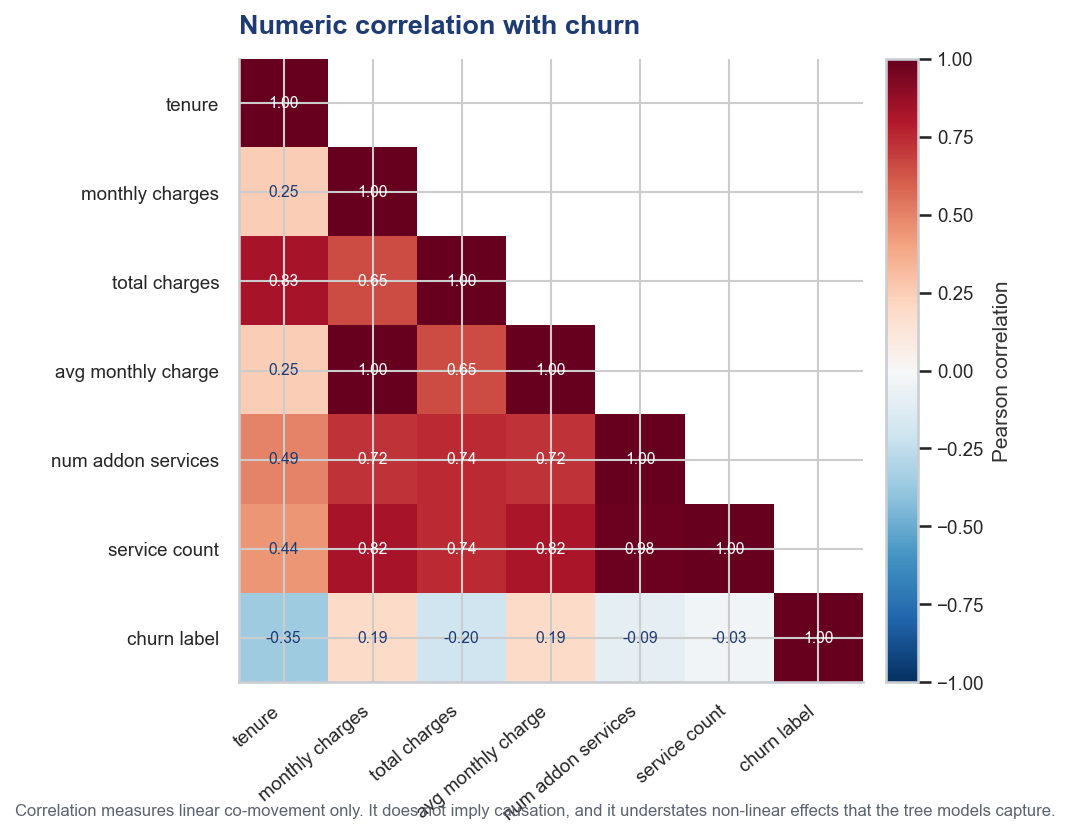

tenure               -0.352229
total_charges        -0.198324
num_addon_services   -0.087698
service_count        -0.030765
monthly_charges       0.193356
churn_label           1.000000
Name: churn_label, dtype: float64

In [14]:
from src.analytics.eda import plot_correlation
show(plot_correlation(df))

numeric = ["tenure", "monthly_charges", "total_charges", "num_addon_services", "service_count", "churn_label"]
df[numeric].corr()["churn_label"].sort_values()

**Observed:** tenure has the strongest linear correlation with churn
(**negative** — longer tenure, less churn). `total_charges` and `monthly_charges`
correlate positively but weakly.

**Why this matters as a warning:** Pearson correlation only captures linear
co-movement, and several strong effects in this data are non-linear (contract type
is categorical; tenure's effect flattens). Correlation here is a screening tool, not
the analysis. It also says nothing about causation — and the correlation between
`tenure` and `total_charges` is largely mechanical, since total charges accumulate
over tenure.

## 9. From description to prediction

The analysis so far says *which attributes travel with churn*. It cannot say which
matter once the others are controlled for, and it cannot rank an individual
customer.

That is the job of the model. Full methodology and metrics are in
`reports/model_evaluation.md`; here we load the trained model's actual output.

In [15]:
from src.models.predict import load_scores, risk_distribution

scored = load_scores()
print(f"Scored customers: {len(scored):,}")
risk_distribution(scored)

Scored customers: 7,043


,risk_category,customers,mean_probability,monthly_revenue,expected_monthly_at_risk,actual_churn_rate,pct_of_customers
0,Very High,382,0.9238,32070.05,29642.44,0.8822,5.42
1,High,1040,0.8124,79799.60,64912.07,0.6337,14.77
2,Medium,2082,0.5651,149344.15,84486.84,0.3314,29.56
3,Low,3539,0.1329,194902.80,28916.41,0.0517,50.25


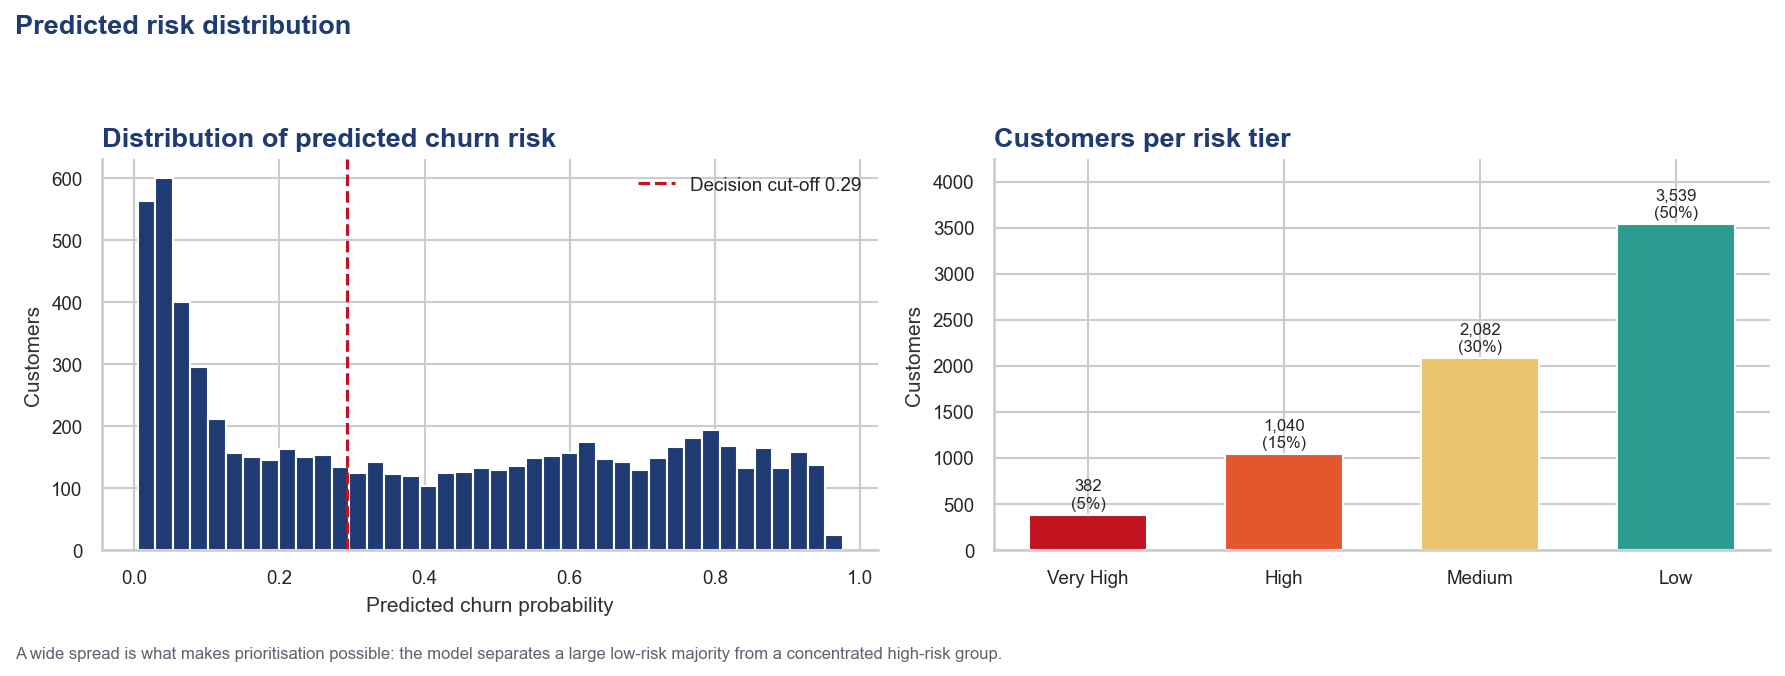

In [16]:
from src.analytics.eda import plot_risk_distribution
show(plot_risk_distribution(scored))

**Observed:** the model separates the base into a **5.4% "Very High"** tier averaging
**0.92** predicted probability and a **50.3% "Low"** tier averaging **0.13**. The
actual churn rate in the Very High tier is **88.2%** — the tiers are real, not
cosmetic.

**Why it matters:** a wide probability spread is what makes prioritisation
possible. If every customer scored near the base rate, no call list could be built.

## 10. Retention prioritisation — the business payoff

In [17]:
from src.retention.prioritization import lift_at_capacity, prioritisation_summary

lift = lift_at_capacity(scored)
lift

,capacity,customers_selected,churners_in_group,churn_rate_in_group,overall_churn_rate,lift,recall_of_churners,precision_of_selection,monthly_revenue_in_group,revenue_share_in_group,expected_monthly_revenue_at_risk
0,0.05,352,314,0.8920,0.2654,3.362,0.1680,0.8920,29683.80,0.0651,27509.52
1,0.10,704,571,0.8111,0.2654,3.056,0.3055,0.8111,57906.95,0.1270,52025.23
2,0.20,1409,990,0.7026,0.2654,2.648,0.5297,0.7026,111025.35,0.2434,93929.82
3,0.30,2113,1310,0.6200,0.2654,2.336,0.7009,0.6200,161918.65,0.3550,128648.50
4,0.50,3522,1691,0.4801,0.2654,1.809,0.9048,0.4801,262518.35,0.5756,179528.54


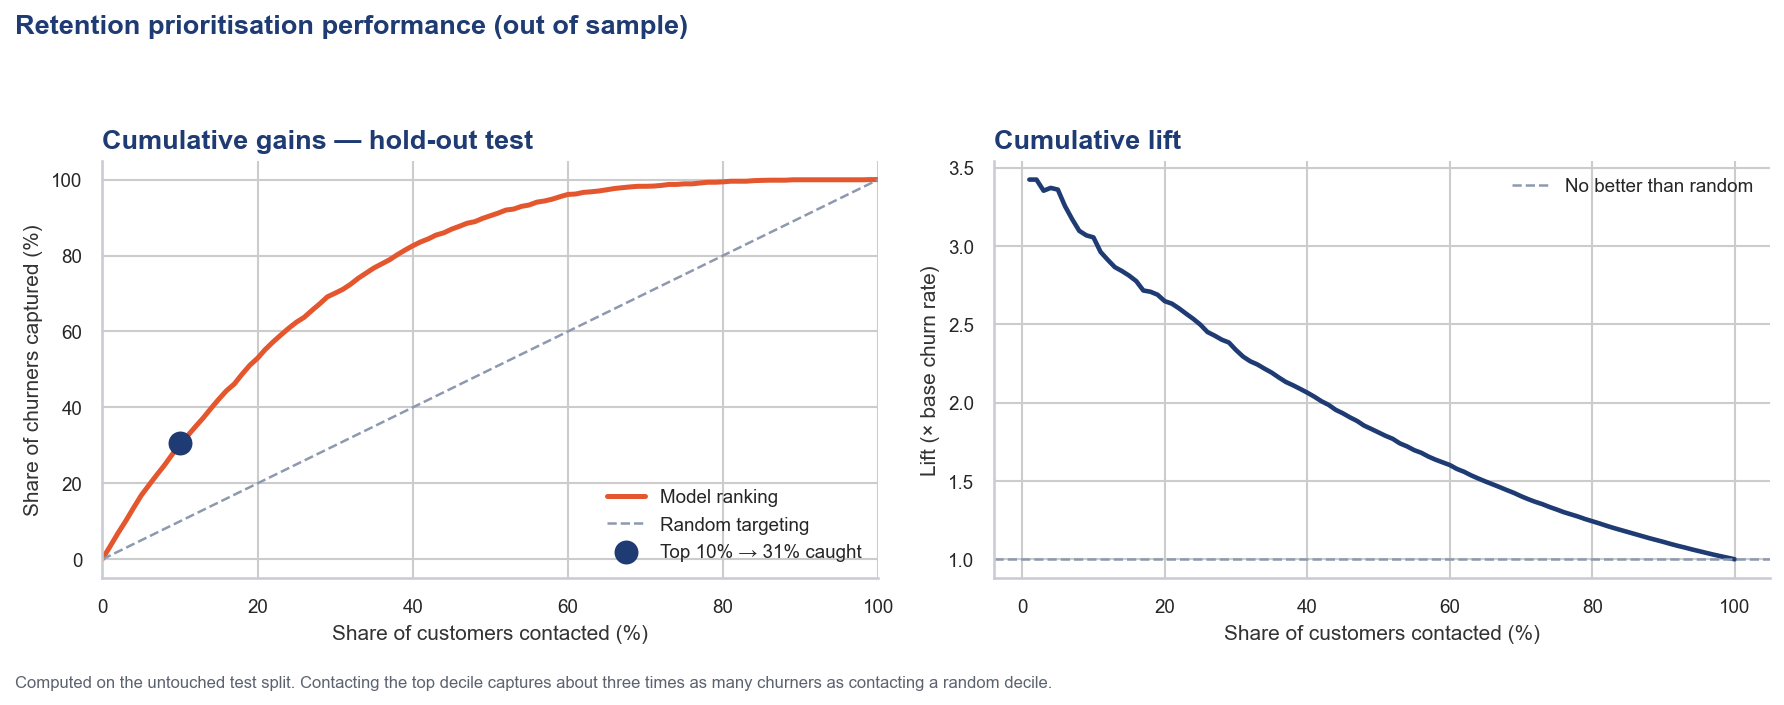

In [18]:
from src.retention.prioritization import cumulative_gains
from src.analytics.eda import plot_lift_curve

primary = lift[lift["capacity"] == 0.10].iloc[0].to_dict()
show(plot_lift_curve(cumulative_gains(scored), primary))

In [19]:
import json
summary = json.loads((config.METRICS_DIR / "retention_summary.json").read_text())["out_of_sample"]
for key, value in summary.items():
    print(f"{key:46s} {value}")

capacity                                       0.1
customers_prioritised                          141
share_of_base_pct                              10.01
avg_predicted_probability                      0.8956
min_predicted_probability_in_group             0.8326
overall_avg_predicted_probability              0.4035
monthly_revenue_in_group                       11329.7
expected_monthly_revenue_at_risk               10168.95
expected_annual_revenue_at_risk                122027.1
share_of_total_monthly_revenue_pct             12.55
contract_mix                                   {'Month-to-month': 1.0}
risk_tier_mix                                  {'Very High': 74, 'High': 67}
has_observed_outcomes                          True
lift_at_capacity                               2.912
churn_rate_in_group                            0.773
overall_churn_rate                             0.2654
churners_captured                              109
recall_of_churners                             0.291

**Observed:** contacting the top **10%** reaches a group where **81.1%** actually
churned, against a **26.5%** base rate — a lift of **3.06×** in-sample. The
out-of-sample figure in the production report (2.91× on the held-out test split) is
the one to quote publicly, because it reflects data the model never saw.

**What the business gets:** the same number of retention calls reaches roughly three
times as many genuine churners as an untargeted list. That is a real, measurable
efficiency gain in *targeting*.

**What it does not get:** proof that contacting them works. No intervention was
run. The revenue figure is exposure, not savings.

## 11. Explaining individual predictions

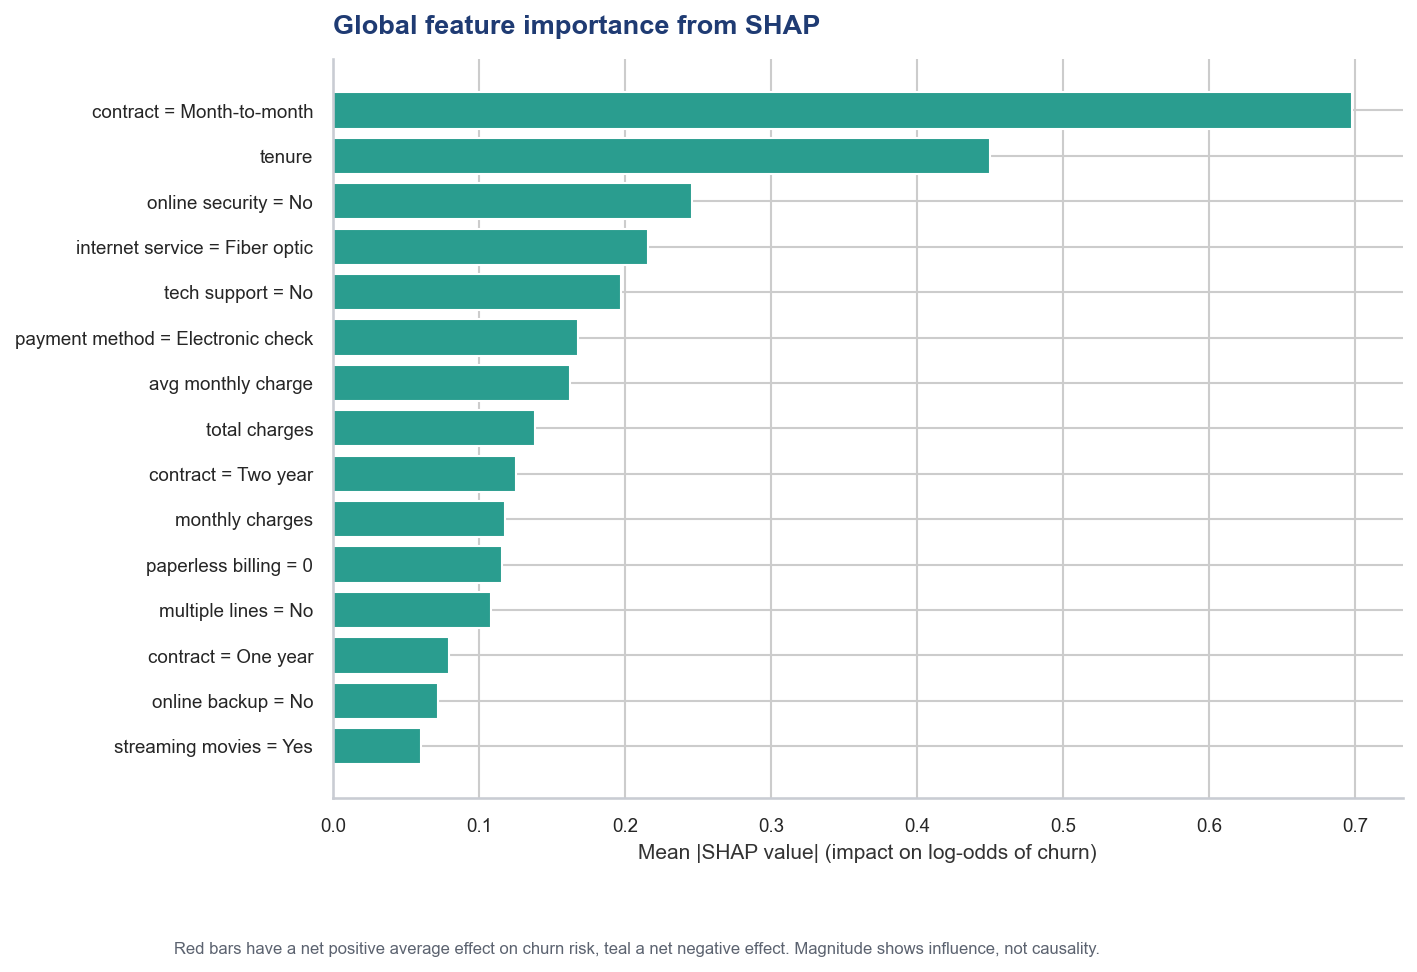

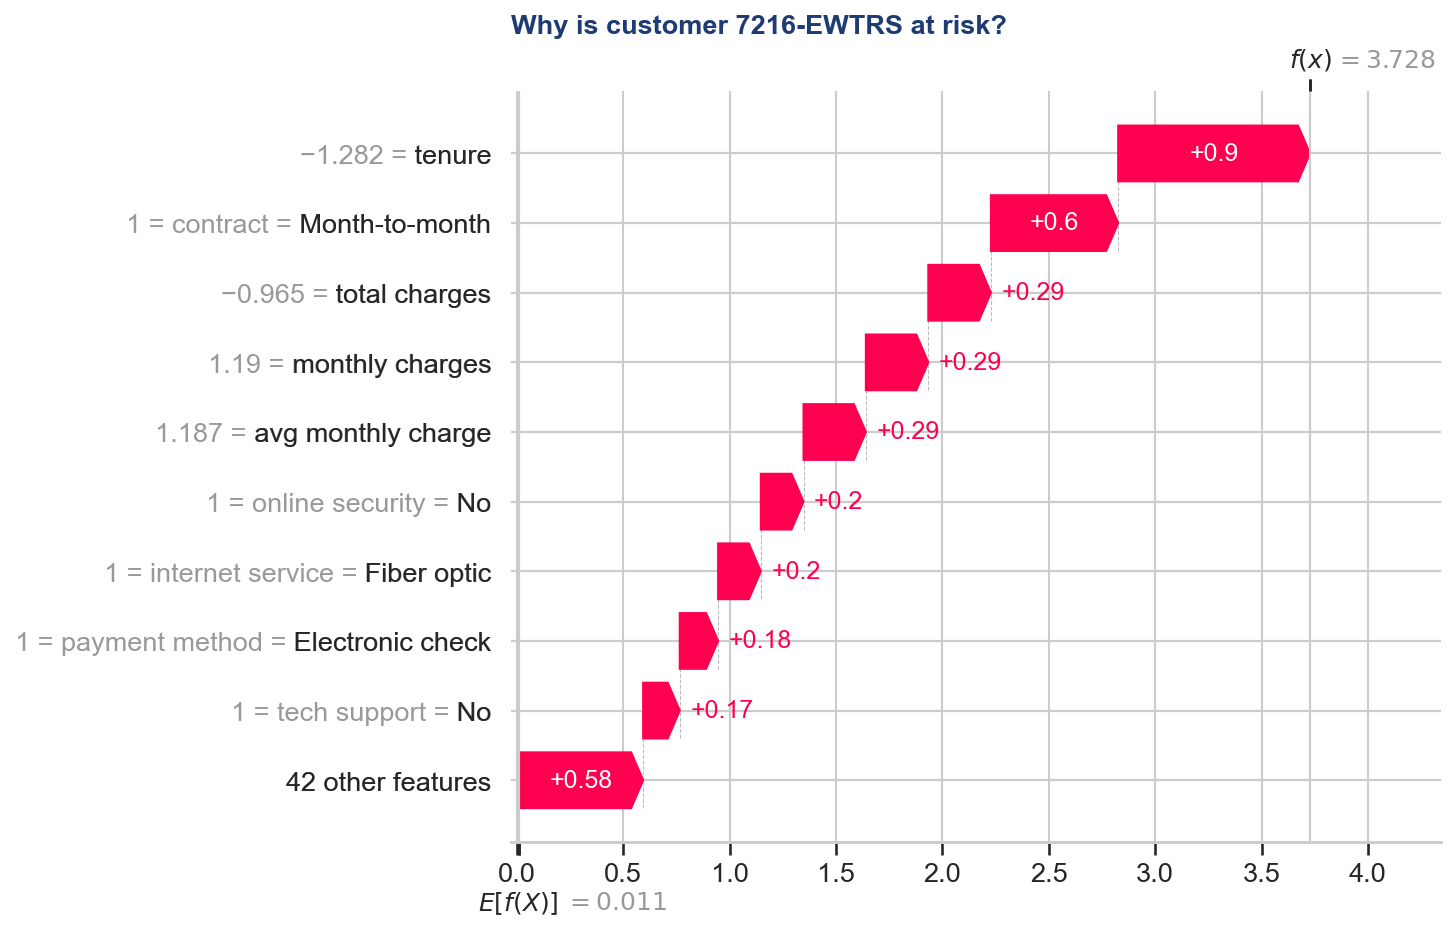

In [20]:
import json
from pathlib import Path

manifest_path = config.DATA_EXPORTS / "explainability" / "explainability_manifest.json"
if manifest_path.exists():
    manifest = json.loads(manifest_path.read_text())
    show(manifest["figures"]["global_importance"])
    show(manifest["figures"]["waterfall"])
else:
    print("Run `python main.py explain` to generate SHAP artefacts.")

In [21]:
if manifest_path.exists():
    individual = json.loads((config.DATA_EXPORTS / "explainability" / "individual_explanation.json").read_text())
    print(f"Customer {individual['customer_id']} — predicted churn probability "
          f"{individual['predicted_probability']:.1%} (base {individual['base_probability']:.1%})")
    print("\nContext:", individual["customer_context"])
    print("\nFactors increasing risk:")
    for factor in individual["risk_increasing_factors"][:5]:
        print(f"  {factor['feature']:45s} {factor['probability_delta_pts']:+7.1f} pts")
    print("\nFactors decreasing risk:")
    for factor in individual["risk_decreasing_factors"][:5]:
        print(f"  {factor['feature']:45s} {factor['probability_delta_pts']:+7.1f} pts")

Customer 7216-EWTRS — predicted churn probability 97.7% (base 50.3%)

Context: {'contract': 'Month-to-month', 'tenure': 1, 'monthly_charges': 100.8, 'internet_service': 'Fiber optic', 'payment_method': 'Electronic check', 'online_security': 'No', 'tech_support': 'No'}

Factors increasing risk:
  tenure                                          +21.1 pts
  contract = Month-to-month                       +14.5 pts
  total charges                                    +7.3 pts
  monthly charges                                  +7.3 pts
  avg monthly charge                               +7.3 pts

Factors decreasing risk:
  contract = One year                              -1.2 pts
  phone service = 0                                -0.3 pts
  num addon services                               -0.1 pts
  device protection = No                           -0.1 pts
  payment method = Bank transfer (automatic)       -0.1 pts


**How to read this:** SHAP attributes the gap between the base rate and this
customer's predicted risk to specific feature values. A positive contribution means
that value pushed the prediction up.

**Feature importance ≠ correlation ≠ causation.** Importance is about what the
model uses. Correlation is about co-movement in the data. Neither establishes that
changing a value would change the outcome. The model is a ranking tool, not a
causal engine.

## 12. Conclusions and recommendations

1. **Churn is front-loaded and structural.** 52.9% of 0–6 month customers leave;
   month-to-month contracts churn at 42.7%. Both point at the same intervention
   window: the first 90 days, before commitment is established.
2. **Exposed revenue is concentrated in high-value, uncommitted customers.**
   Month-to-month Mid-High/High band customers churn above 52% while carrying
   disproportionate monthly revenue.
3. **The model is usable, not perfect.** Test PR-AUC 0.658 against a 0.265 base
   rate; at the tuned threshold it catches ~92% of churners but roughly half the
   flagged customers stay. That trade-off is deliberate and should be revisited
   with real campaign economics.
4. **Prioritisation delivers ~3× lift.** The top decile churns at roughly three
   times the base rate on held-out data. Same call capacity, three times the
   churners reached.
5. **Nothing here proves retention works.** No intervention was run and no save
   rate exists. The honest next step is a controlled pilot with a holdout group,
   tracked against cost per save.

Business recommendations, the full limitations section and the additional data
that would materially improve this are in `reports/business_insights.md`.